In [1]:
import numpy as np

In [2]:
X = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [3, 3],
    [4, 3],
    [3, 4],
    [4, 5],
    [5, 4]
])

In [3]:
y = np.array([0, 0, 0, 1, 1, 1, 1, 1])

In [4]:
X.shape, y.shape

((8, 2), (8,))

In [5]:
def initialize_parameters(X):
    w = np.zeros(X.shape[1])
    b=0

    return w,b


In [10]:
def predict(x, w, b):
    z = np.dot(x, w) + b
    return 1 if z > 0 else 0

In [ ]:
def train(X, y, lr, epochs):

    w , b = initialize_parameters(X)
    
    for epoch in range(epochs):
        indices = np.random.permutation(len(X))

        for i in indices:
            x_i = X[i]
            y_i = y[i]

            y_pred = predict(x_i, w, b)

            z = np.dot(x_i, w ) + b

            error=y_i - y_pred

            w = w + lr * error * x_i 

            b = b + lr * error

    return w, b


        

In [15]:
w, b = train(X, y, lr=0.1, epochs=10)

In [16]:
w,b

(array([0.1, 0.2]), np.float64(-0.7999999999999999))

In [17]:
y_pred = np.array([predict(x, w, b) for x in X])

print("Actual:", y)
print("Predicted:", y_pred)

Actual: [0 0 0 1 1 1 1 1]
Predicted: [0 0 0 1 1 1 1 1]


In [18]:
accuracy = np.mean(y == y_pred)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [22]:
import matplotlib.pyplot as plt

def plot_decision_boundary(X, y, w, b):
    plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1")

    x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    x2 = -(w[0] * x1 + b) / w[1]

    plt.plot(x1, x2, color="black", label="Decision boundary")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.grid(True)
    plt.show()

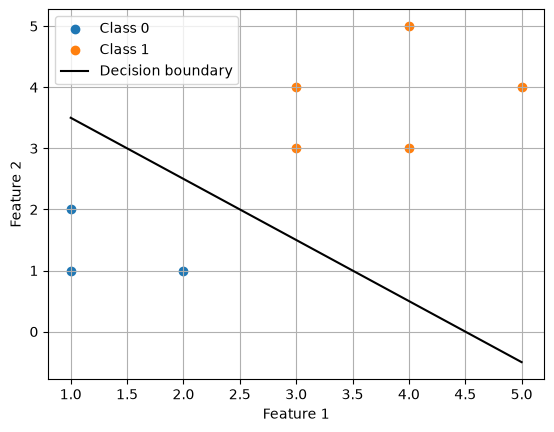

In [23]:
plot_decision_boundary(X, y, w, b)

In [24]:
np.random.seed(42)

n = 100

X = np.random.uniform(0, 10, (n, 2))

noise = np.random.normal(0, 1.5, n)

y = (X[:, 0] + X[:, 1] + noise > 10).astype(int)

In [25]:
w, b = train(X, y, lr=0.1, epochs=10)

y_pred = np.array([predict(x, w, b) for x in X])

accuracy = np.mean(y == y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.87


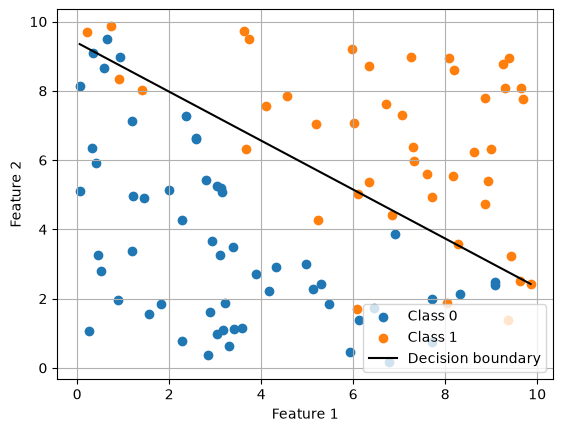

In [26]:
plot_decision_boundary(X, y, w, b)

In [27]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
def binary_cross_entropy(y, y_pred):
    loss = -(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    return np.mean(loss)

In [29]:
def train_gradient_descent(X, y, lr, epochs):
    w = np.zeros(X.shape[1])
    b = 0.0
    n = len(X)

    for epoch in range(epochs):
        y_pred = sigmoid(X @ w + b)

        dw = X.T @ (y_pred - y) / n
        db = np.mean(y_pred - y)

        w = w - lr * dw
        b = b - lr * db

    return w, b

In [53]:
w_gd, b_gd = train_gradient_descent(X, y, lr=0.3, epochs=1000)

In [54]:
y_prob_gd = sigmoid(X @ w_gd + b_gd)

loss_gd = binary_cross_entropy(y, y_prob_gd)

print("Gradient Descent Loss:", loss_gd)

Gradient Descent Loss: 0.2294957362094255


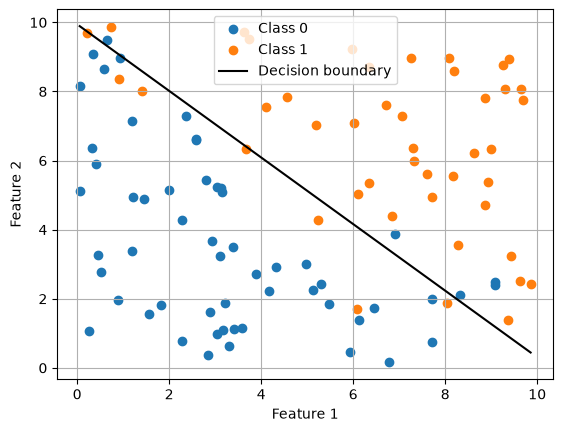

In [55]:
plot_decision_boundary(X, y, w_gd, b_gd)

In [ ]:
y_prob_perceptron = sigmoid(X @ w + b)
y_prob_gd = sigmoid(X @ w_gd + b_gd)

loss_perceptron = binary_cross_entropy(y, y_prob_perceptron)
loss_gd = binary_cross_entropy(y, y_prob_gd)

print("Perceptron Trick BCE:", loss_perceptron)
print("Gradient Descent BCE:", loss_gd)

Perceptron Trick BCE: 0.28120592706097713
Gradient Descent BCE: 0.2294957362094255


In [58]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


In [59]:
# Perceptron trick
w_p, b_p = train(X_train, y_train, lr=0.1, epochs=100)

# Gradient descent with binary cross-entropy
w_gd, b_gd = train_gradient_descent(
    X_train, y_train, lr=0.1, epochs=1000
)

In [60]:
# Perceptron trick
y_prob_p = sigmoid(X_test @ w_p + b_p)
loss_p = binary_cross_entropy(y_test, y_prob_p)

# Gradient descent
y_prob_gd = sigmoid(X_test @ w_gd + b_gd)
loss_gd = binary_cross_entropy(y_test, y_prob_gd)

print("Perceptron Trick Test BCE:", loss_p)
print("Gradient Descent Test BCE:", loss_gd)

Perceptron Trick Test BCE: 0.8379540645092828
Gradient Descent Test BCE: 0.29507523764550736


In [64]:
# Perceptron Trick
y_pred_perceptron = (X_test @ w_p + b_p > 0).astype(int)
accuracy_perceptron = np.mean(y_pred_perceptron == y_test)

# Gradient Descent
y_pred_gd = (X_test @ w_gd + b_gd >= 0).astype(int)
accuracy_gd = np.mean(y_pred_gd == y_test)

print("Perceptron Trick Test Accuracy:", accuracy_perceptron)
print("Gradient Descent Test Accuracy:", accuracy_gd)

Perceptron Trick Test Accuracy: 0.65
Gradient Descent Test Accuracy: 0.9



## Scope

- Implement the perceptron trick and gradient descent with binary cross-entropy from scratch using NumPy.
- Support datasets with an arbitrary number of numerical features (n-dimensional feature vectors).
- Use vectorized NumPy operations for efficient computation.
- Visualize the decision boundary for two-feature datasets.
- Compare both approaches using training BCE, test BCE, and test accuracy.

## Assumptions

- The task is binary classification with labels 0 and 1.
- Each sample contains n numerical features, represented by a feature vector.
- The number of weights is determined automatically from the number of input features.
- The perceptron uses a step-function decision rule and does not use sigmoid.
- The gradient descent model uses sigmoid activation and binary cross-entropy loss.
- Both models use the same training and test split for a fair comparison.
- Decision boundary visualization is limited to two-feature datasets, although the models can operate on higher-dimensional feature vectors.
- A single train-test split provides an initial estimate of generalization performance, not a guarantee.

## Results and Comparison

| Metric | Perceptron Trick | Gradient Descent + BCE |
|---|---:|---:|
| Training BCE | 0.2812 | 0.2295 |
| Test BCE | 0.8380 | 0.2951 |
| Test Accuracy | 65% | 90% |

**Note:** BCE for the perceptron was calculated by applying sigmoid to its scores for evaluation. Sigmoid is not part of the perceptron algorithm itself, so the BCE comparison is not a direct comparison of the models' training objectives.

## Conclusion

Both implementations determine the number of weights dynamically from the number of input features, allowing them to handle n-dimensional feature vectors. The current visualization function is restricted to two features.

On this dataset and test split, gradient descent with binary cross-entropy achieved higher test accuracy and lower test BCE. Further evaluation is needed to determine whether this advantage generalizes to other datasets.
